=== 多核满血版纯 BEM 求解二维弹性受压方板 ===
E = 1.0e+06 Pa, nu = 0.3, 网格数 N = 800
正在编译并多核组装矩阵...
H, G 矩阵组装完成，耗时: 1.648 s
线性方程组求逆完成，耗时: 0.049 s 
正在多核全速计算域内物理场 (含4倍有限差分)...
全域位移与偏导数提取完成，耗时: 1.959 s 


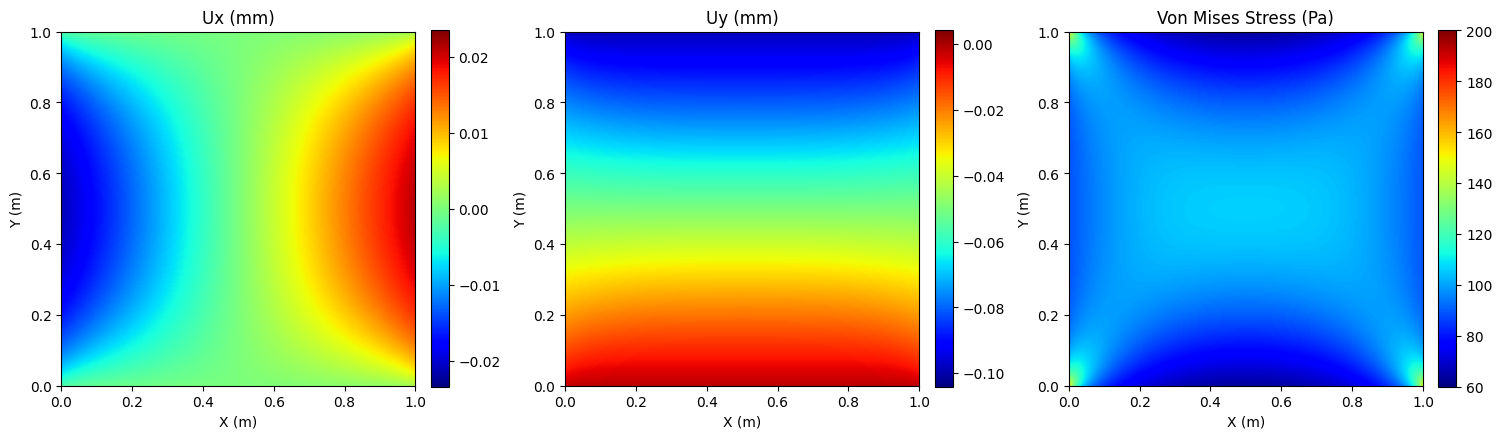

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
import time

# ==========================================
# 1. 物理参数与网格参数
# ==========================================
L = 1.0              # 正方形边长 (m)
E = 1.0e6            # 杨氏模量 (Pa)
nu = 0.3             # 泊松比
disp_top = -1e-4     # 顶边法向位移 (m)

nu_eff = nu 
G_shear = E / (2.0 * (1.0 + nu))

n_per_side = 200      # 每边单元数 (总数 N = 800)
N = n_per_side * 4

print(f"=== 多核满血版纯 BEM 求解二维弹性受压方板 ===")
print(f"E = {E:.1e} Pa, nu = {nu}, 网格数 N = {N}")

# ==========================================
# 2. 生成常数边界单元网格
# ==========================================
nodes = np.zeros((N, 2))
normals = np.zeros((N, 2))
lengths = np.zeros(N)
edge_ids = np.zeros(N, dtype=int)

dl = L / n_per_side
coords = np.linspace(dl/2, L - dl/2, n_per_side)

idx = 0
for x in coords:
    nodes[idx] = [x, 0]; normals[idx] = [0, -1]; lengths[idx] = dl; edge_ids[idx] = 0; idx += 1
for y in coords:
    nodes[idx] = [L, y]; normals[idx] = [1, 0]; lengths[idx] = dl; edge_ids[idx] = 1; idx += 1
for x in coords[::-1]:
    nodes[idx] = [x, L]; normals[idx] = [0, 1]; lengths[idx] = dl; edge_ids[idx] = 2; idx += 1
for y in coords[::-1]:
    nodes[idx] = [0, y]; normals[idx] = [-1, 0]; lengths[idx] = dl; edge_ids[idx] = 3; idx += 1

# 常数提前计算好，以标量形式传入 Numba，加速极速
C1 = 1.0 / (8.0 * np.pi * G_shear * (1.0 - nu_eff))
C2 = 3.0 - 4.0 * nu_eff
C3 = -1.0 / (4.0 * np.pi * (1.0 - nu_eff))
C4 = 1.0 - 2.0 * nu_eff
gauss_xi, gauss_w = np.polynomial.legendre.leggauss(4)

# ==========================================
# 3. Numba 并行内核：组装 H 和 G 矩阵
# ==========================================
@njit(parallel=True)
def assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4):
    N = nodes.shape[0]
    H = np.zeros((2*N, 2*N))
    G = np.zeros((2*N, 2*N))
    n_gauss = len(gauss_xi)
    
    # prange 开启多线程并行，所有 CPU 核心将被瞬间拉满！
    for i in prange(N):
        x_source = nodes[i]
        for j in range(N):
            L_j = lengths[j]
            nx = normals[j, 0]; ny = normals[j, 1]
            tx = -ny; ty = nx
            
            r0 = 2*i; r1 = 2*i+1
            c0 = 2*j; c1 = 2*j+1
            
            if i == j:
                H[r0, c0] = 0.5; H[r0, c1] = 0.0
                H[r1, c0] = 0.0; H[r1, c1] = 0.5
                
                g00 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)) + 1.0)
                g11 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)))
                
                # 手工展开矩阵旋转相乘，避开 python 对象的创建开销
                G[r0, c0] = tx * (g00 * tx) + nx * (g11 * nx)
                G[r0, c1] = tx * (g00 * ty) + nx * (g11 * ny)
                G[r1, c0] = ty * (g00 * tx) + ny * (g11 * nx)
                G[r1, c1] = ty * (g00 * ty) + ny * (g11 * ny)
            else:
                y_center = nodes[j]
                H00 = 0.0; H01 = 0.0; H10 = 0.0; H11 = 0.0
                G00 = 0.0; G01 = 0.0; G10 = 0.0; G11 = 0.0
                
                for g in range(n_gauss):
                    y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                    y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                    
                    rx = y_gpx - x_source[0]
                    ry = y_gpy - x_source[1]
                    r = np.sqrt(rx*rx + ry*ry)
                    
                    rdx = rx / r; rdy = ry / r
                    dr_dn = rdx * nx + rdy * ny
                    log_1_r = np.log(1.0 / r)
                    
                    hw = 0.5 * L_j * gauss_w[g]
                    
                    # 彻底标量化展开 U_star 和 T_star，剔除一切 numpy 数组创建
                    G00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                    G01 += C1 * (rdx*rdy) * hw
                    G10 += C1 * (rdx*rdy) * hw
                    G11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                    
                    H00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                    H01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                    H10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                    H11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                    
                H[r0, c0] = H00; H[r0, c1] = H01
                H[r1, c0] = H10; H[r1, c1] = H11
                G[r0, c0] = G00; G[r0, c1] = G01
                G[r1, c0] = G10; G[r1, c1] = G11
                
    return H, G

t0 = time.time()
print("正在编译并多核组装矩阵...")
H, G = assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4)
print(f"H, G 矩阵组装完成，耗时: {time.time()-t0:.3f} s")

# ==========================================
# 4. 施加边界条件与线性求解 (保持不变)
# ==========================================
A = np.zeros((2*N, 2*N))
B = np.zeros(2*N)
u_known = np.zeros(2*N, dtype=bool); u_val = np.zeros(2*N)
t_known = np.zeros(2*N, dtype=bool); t_val = np.zeros(2*N)

for i in range(N):
    eid = edge_ids[i]
    dof_x, dof_y = 2*i, 2*i+1
    
    if eid == 0:   
        u_known[dof_x] = True; u_val[dof_x] = 0.0
        u_known[dof_y] = True; u_val[dof_y] = 0.0
    elif eid == 2: 
        # 注意这里已经修复为了 u_x = 0 (不滑移摩擦边界)
        u_known[dof_x] = True; u_val[dof_x] = 0.0
        u_known[dof_y] = True; u_val[dof_y] = disp_top
    else:          
        t_known[dof_x] = True; t_val[dof_x] = 0.0
        t_known[dof_y] = True; t_val[dof_y] = 0.0

for k in range(2*N):
    if u_known[k]:
        A[:, k] = -G[:, k]
        B -= H[:, k] * u_val[k]
    else:
        A[:, k] = H[:, k]
        B += G[:, k] * t_val[k]

t1 = time.time()
X = np.linalg.solve(A, B)
print(f"线性方程组求逆完成，耗时: {time.time()-t1:.3f} s ")

u_bnd = np.zeros(2*N)
t_bnd = np.zeros(2*N)
for k in range(2*N):
    if u_known[k]:
        u_bnd[k] = u_val[k]; t_bnd[k] = X[k]
    else:
        u_bnd[k] = X[k]; t_bnd[k] = t_val[k]

# ==========================================
# 5. Numba 并行内核：极速计算内部场
# ==========================================
@njit(parallel=True)
def calc_internal_u_numba(pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd):
    N_pts = pts.shape[0]
    N = nodes.shape[0]
    n_gauss = len(gauss_xi)
    u_out = np.zeros((N_pts, 2))
    
    for q in prange(N_pts):
        xi_x = pts[q, 0]; xi_y = pts[q, 1]
        u_x = 0.0; u_y = 0.0
        
        for j in range(N):
            y_center = nodes[j]
            L_j = lengths[j]
            nx = normals[j, 0]; ny = normals[j, 1]
            tx = -ny; ty = nx
            
            U00 = 0.0; U01 = 0.0; U10 = 0.0; U11 = 0.0
            T00 = 0.0; T01 = 0.0; T10 = 0.0; T11 = 0.0
            
            for g in range(n_gauss):
                y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                
                rx = y_gpx - xi_x; ry = y_gpy - xi_y
                r = np.sqrt(rx*rx + ry*ry)
                rdx = rx / r; rdy = ry / r
                dr_dn = rdx * nx + rdy * ny
                log_1_r = np.log(1.0 / r)
                hw = 0.5 * L_j * gauss_w[g]
                
                U00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                U01 += C1 * (rdx*rdy) * hw
                U10 += C1 * (rdx*rdy) * hw
                U11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                
                T00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                T01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                T10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                T11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                
            uj_x = u_bnd[2*j]; uj_y = u_bnd[2*j+1]
            tj_x = t_bnd[2*j]; tj_y = t_bnd[2*j+1]
            
            u_x += (U00*tj_x + U01*tj_y) - (T00*uj_x + T01*uj_y)
            u_y += (U10*tj_x + U11*tj_y) - (T10*uj_x + T11*uj_y)
            
        u_out[q, 0] = u_x
        u_out[q, 1] = u_y
        
    return u_out

print("正在多核全速计算域内物理场 (含4倍有限差分)...")
grid_size = 200
coords_1d = np.linspace(0.02, 0.98, grid_size)
XX, YY = np.meshgrid(coords_1d, coords_1d)
internal_pts = np.c_[XX.ravel(), YY.ravel()]

t2 = time.time()
u_int = calc_internal_u_numba(internal_pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

eps_delta = 1e-4
u_px = calc_internal_u_numba(internal_pts + np.array([eps_delta, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_mx = calc_internal_u_numba(internal_pts - np.array([eps_delta, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_py = calc_internal_u_numba(internal_pts + np.array([0.0, eps_delta]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_my = calc_internal_u_numba(internal_pts - np.array([0.0, eps_delta]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

du_dx = (u_px - u_mx) / (2*eps_delta)
du_dy = (u_py - u_my) / (2*eps_delta)
print(f"全域位移与偏导数提取完成，耗时: {time.time()-t2:.3f} s ")

# 后处理应变与应力
eps_xx = du_dx[:, 0]
eps_yy = du_dy[:, 1]
eps_xy = 0.5 * (du_dx[:, 1] + du_dy[:, 0])

lam = E * nu / ((1 + nu) * (1 - 2 * nu))
mu_lame = E / (2 * (1 + nu))

sig_xx = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_xx
sig_yy = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_yy
sig_xy = 2 * mu_lame * eps_xy

# 【关键修正】：平面应变状态下，Z方向存在约束反力！
sig_zz = nu * (sig_xx + sig_yy)

# 使用完整的三维 Von Mises 公式
von_mises = np.sqrt(0.5 * ((sig_xx - sig_yy)**2 + 
                           (sig_yy - sig_zz)**2 + 
                           (sig_zz - sig_xx)**2) + 
                    3 * sig_xy**2)

# ==========================================
# 6. 绘图与出图
import matplotlib.gridspec as gridspec

def _pad_limits(values, pad_ratio=0.06):
    values = np.asarray(values, dtype=float)
    lo = float(np.min(values))
    hi = float(np.max(values))
    span = hi - lo
    if span <= 1e-15:
        span = max(abs(lo), abs(hi), 1.0)
    pad = pad_ratio * span
    return lo - pad, hi + pad

BEM_PLOT_LIMITS = {
    "ux": _pad_limits(u_int[:, 0] * 1e3, pad_ratio=0.06),
    "uy": _pad_limits(u_int[:, 1] * 1e3, pad_ratio=0.06),
    "von_mises": (60.0, 200.0),
}

fig = plt.figure(figsize=(18, 5))

extent = [0, L, 0, L]

# 使用 GridSpec 控制颜色条和子图对齐
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.3)

# Ux
ax0 = fig.add_subplot(gs[0, 0])
im0 = ax0.imshow(
    u_int[:, 0].reshape(grid_size, grid_size) * 1e3,
    origin='lower',
    extent=extent,
    cmap='jet',
    aspect='equal',
    vmin=BEM_PLOT_LIMITS["ux"][0],
    vmax=BEM_PLOT_LIMITS["ux"][1],
)
ax0.set_xlabel('X (m)'); ax0.set_ylabel('Y (m)')
# 色条和子图等高
cbar0 = fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
ax0.set_title('Ux (mm)')

# Uy
ax1 = fig.add_subplot(gs[0, 1])
im1 = ax1.imshow(
    u_int[:, 1].reshape(grid_size, grid_size) * 1e3,
    origin='lower',
    extent=extent,
    cmap='jet',
    aspect='equal',
    vmin=BEM_PLOT_LIMITS["uy"][0],
    vmax=BEM_PLOT_LIMITS["uy"][1],
)
ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)')
cbar1 = fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_title('Uy (mm)')

# Von Mises
ax2 = fig.add_subplot(gs[0, 2])
im2 = ax2.imshow(
    von_mises.reshape(grid_size, grid_size),
    origin='lower',
    extent=extent,
    cmap='jet',
    aspect='equal',
    vmin=BEM_PLOT_LIMITS["von_mises"][0],
    vmax=BEM_PLOT_LIMITS["von_mises"][1],
)
ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)')
cbar2 = fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title('Von Mises Stress (Pa)')

plt.show()

PINN方板受压

device: cuda
=== 传统物理信息神经网络 (Vanilla PINN) 求解 ===
归一化参数: E* = 1.0, 顶部施加位移 U* = -1.0
fixed collocation: interior=8000, each boundary=400
loss weights: PDE=1.0, displacement BC=100.0, traction BC=10.0
Start Vanilla PINN training with fixed collocation points...
Epoch     0 | Total: 6.8274e+00 | PDE: 8.8854e-02 | DispBC: 0.0000e+00 | TracBC: 6.7385e-01
Epoch   500 | Total: 1.7666e+00 | PDE: 3.4989e-01 | DispBC: 0.0000e+00 | TracBC: 1.4168e-01
Epoch  1000 | Total: 1.5363e+00 | PDE: 3.8929e-01 | DispBC: 0.0000e+00 | TracBC: 1.1471e-01
Epoch  1500 | Total: 1.4299e+00 | PDE: 4.1411e-01 | DispBC: 0.0000e+00 | TracBC: 1.0158e-01
Epoch  1999 | Total: 1.3980e+00 | PDE: 3.8914e-01 | DispBC: 0.0000e+00 | TracBC: 1.0088e-01
Adam pretraining done, time: 46.66 s
Start L-BFGS refinement with deterministic closure...
L-BFGS eval   100 | Total: 1.3562e+00 | PDE: 4.1514e-01 | DispBC: 0.0000e+00 | TracBC: 9.4105e-02
L-BFGS eval   200 | Total: 1.3111e+00 | PDE: 3.8622e-01 | DispBC: 0.0000e+00 | TracBC: 9.24

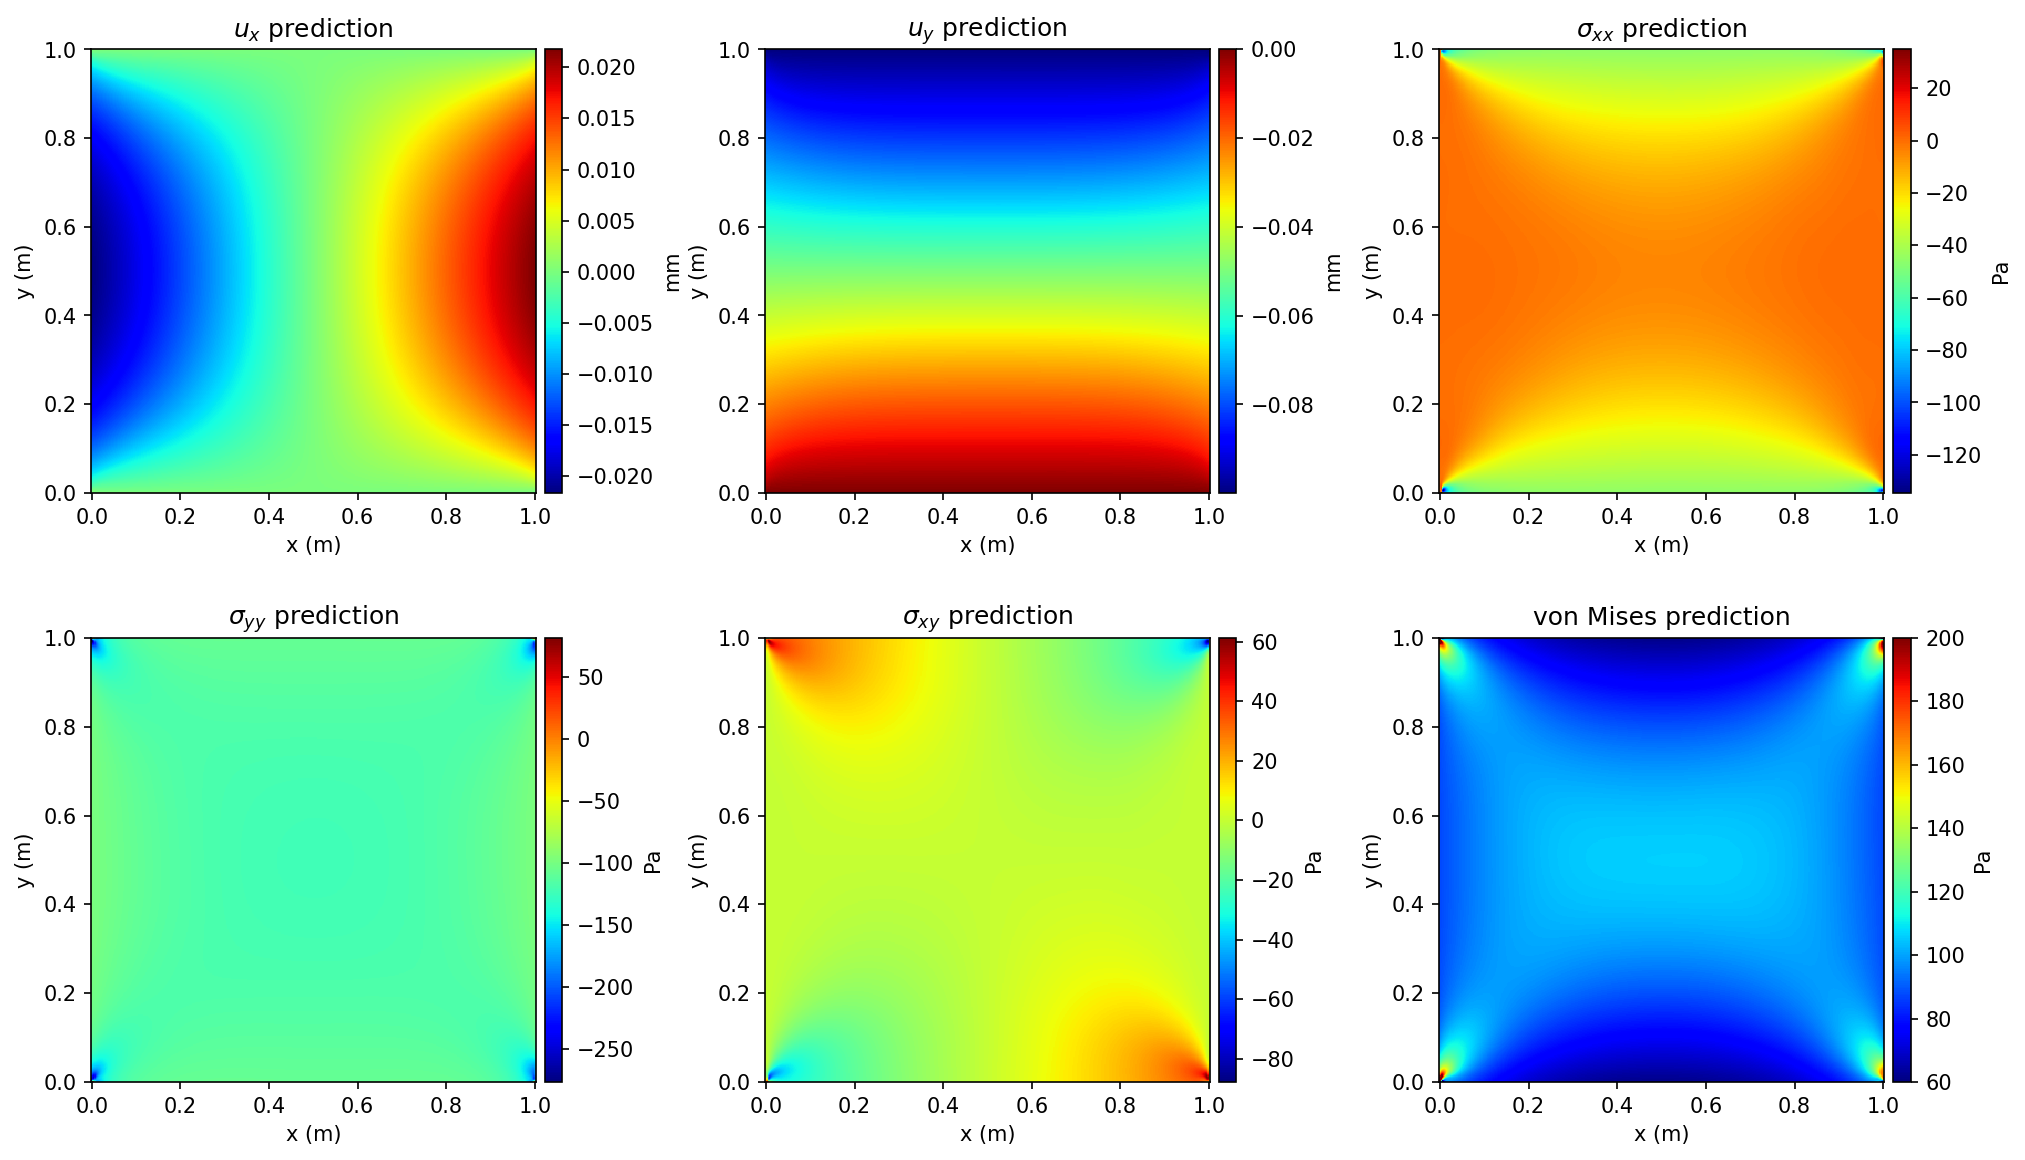

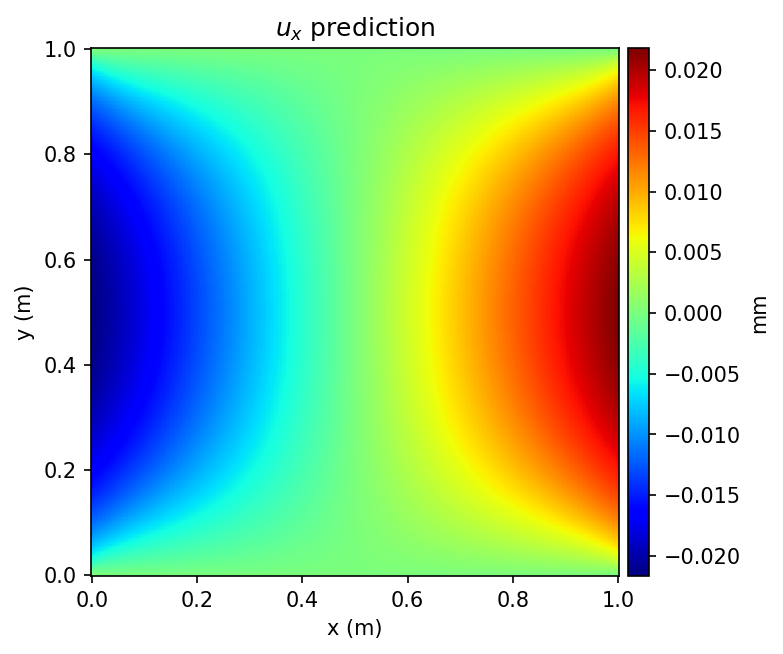

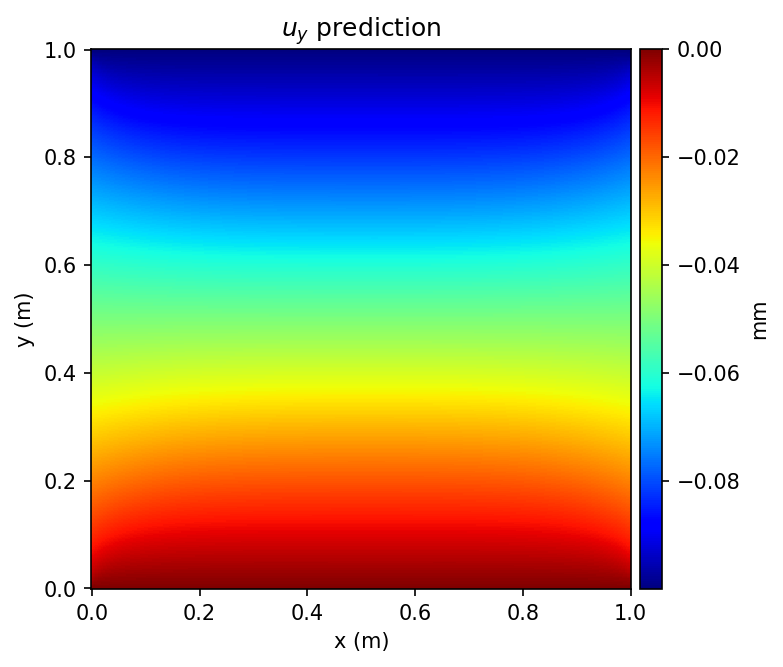

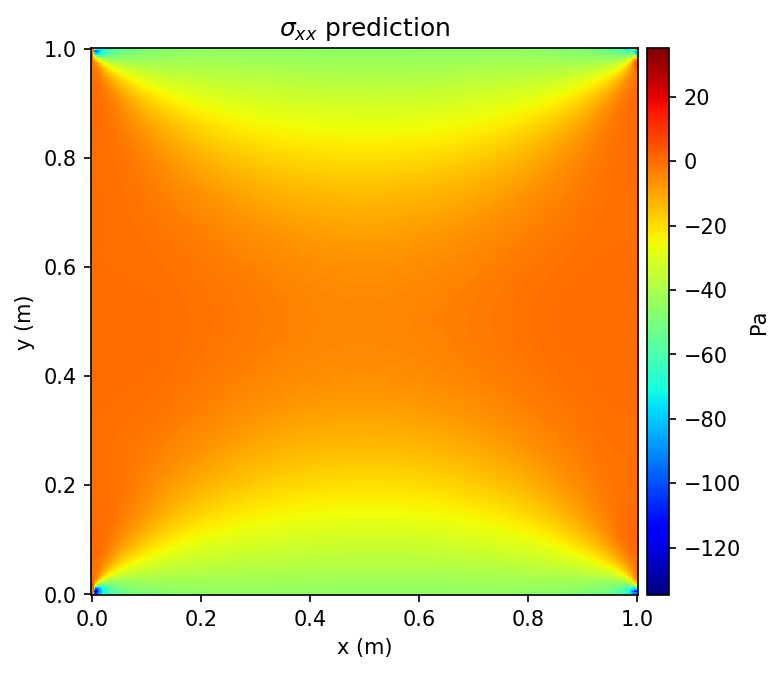

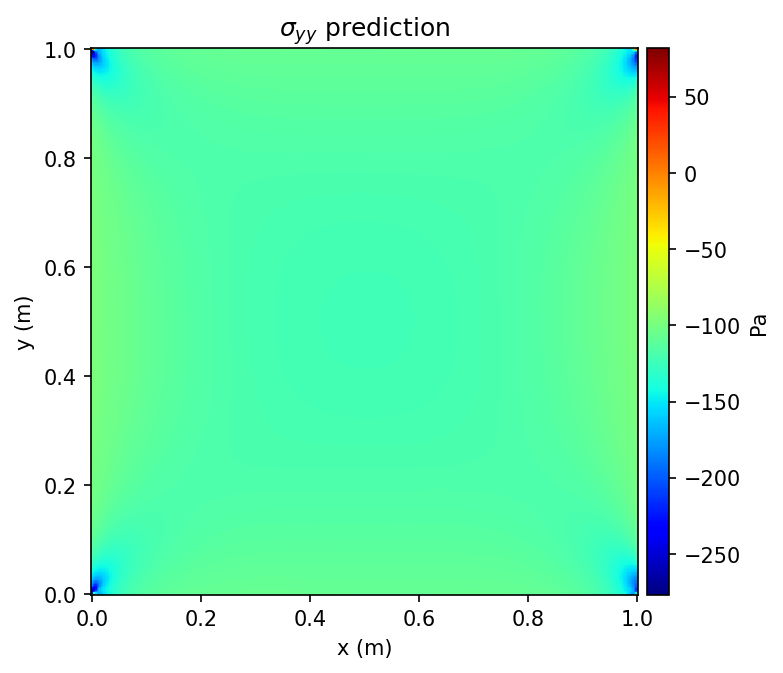

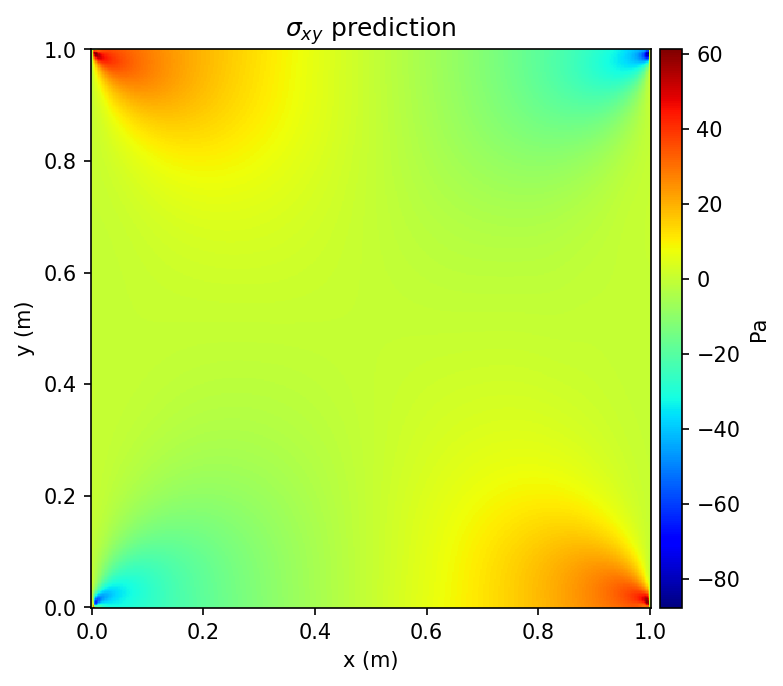

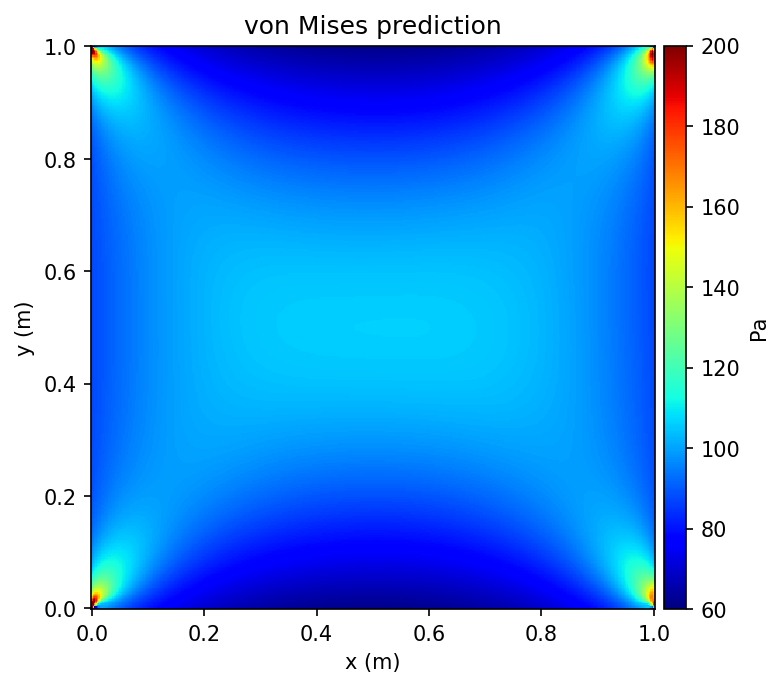

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time

# Reproducible training for numerical experiments.
torch.manual_seed(1234)
np.random.seed(1234)

# Use GPU if available, otherwise CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")

# ==========================================
# 1. 物理参数与量纲归一化 (与 CV-PINN 保持绝对一致)
# ==========================================
L = 1.0              # 正方形边长 (m)
E_real = 1.0e6       # 真实杨氏模量 (Pa)
nu = 0.3             # 泊松比
disp_top_real = -1e-4# 顶边法向位移 (m)

# 无量纲化
scale_u = 1e4        
E = 1.0              
disp_top = disp_top_real * scale_u  

# 平面应变拉梅常数 (Lame parameters)
lam = (E * nu) / ((1 + nu) * (1 - 2 * nu))
mu = E / (2 * (1 + nu))

print(f"=== 传统物理信息神经网络 (Vanilla PINN) 求解 ===")
print(f"归一化参数: E* = {E}, 顶部施加位移 U* = {disp_top}")

# ==========================================
# 2. 构建标准实数神经网络 (MLP)
# ==========================================
class VanillaPINN(nn.Module):
    def __init__(self, hidden=50):
        super().__init__()
        # 传统的实数全连接层，输入 (x,y)，输出 (ux, uy)
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.Tanh(), # 必须用 Tanh/SiLU 等平滑激活函数，ReLU无法求二阶导
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 2)
        )

    def forward(self, x, y):
        # 拼接 x, y 作为输入
        xy = torch.cat([x, y], dim=1)
        raw = self.net(xy)
        raw_u = raw[:, 0:1]
        raw_v = raw[:, 1:2]

        # Hard displacement constraints on y=0 and y=1:
        # ux=0 on bottom/top, uy=0 on bottom, uy=disp_top on top.
        u = y * (1.0 - y) * raw_u
        v = y * disp_top + y * (1.0 - y) * raw_v
        return u, v

# A slightly wider network helps represent stress fields computed from derivatives.
model = VanillaPINN(hidden=80).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# 自动求导辅助函数
def grad(outputs, inputs):
    return torch.autograd.grad(outputs, inputs, grad_outputs=torch.ones_like(outputs), create_graph=True)[0]

# ==========================================
# 3. 损失函数定义 (PDE 内部损失 + 边界损失)
# ==========================================
# 3. Fixed collocation points and loss function
# ==========================================
# L-BFGS needs a deterministic closure. Therefore the collocation points are fixed
# for both Adam pretraining and L-BFGS refinement.
# If memory is tight, reduce N_IN_TRAIN to 4000 and N_BND_TRAIN to 300 first.
N_IN_TRAIN = 8000
N_BND_TRAIN = 400
ADAM_EPOCHS = 2000
LBFGS_MAX_ITER = 10000
PDE_WEIGHT = 1.0
DISP_BC_WEIGHT = 100.0
TRACTION_BC_WEIGHT = 10.0

# Normalized plane-strain Lame constants used by D-PINN.
# Keep them local and explicit so later notebook cells cannot overwrite stress recovery.
E_PINN_NORM = 1.0
LAM_PINN = (E_PINN_NORM * nu) / ((1.0 + nu) * (1.0 - 2.0 * nu))
MU_PINN = E_PINN_NORM / (2.0 * (1.0 + nu))


def make_training_points(n_in=N_IN_TRAIN, n_b=N_BND_TRAIN):
    """Create fixed Sobol interior points and corner-clustered boundary points."""
    sobol = torch.quasirandom.SobolEngine(dimension=2, scramble=True, seed=1234)
    xy_in = sobol.draw(int(n_in)).to(device)
    eps = torch.tensor(1e-6, device=device)
    x_in = torch.clamp(xy_in[:, 0:1], eps.item(), 1.0 - eps.item())
    y_in = torch.clamp(xy_in[:, 1:2], eps.item(), 1.0 - eps.item())

    # Chebyshev-type boundary points: no exact corners, but much denser near corners.
    k = torch.arange(1, int(n_b) + 1, device=device, dtype=torch.float32).view(-1, 1)
    t_bnd = 0.5 * (1.0 - torch.cos(torch.pi * k / (int(n_b) + 1)))
    return {"x_in": x_in, "y_in": y_in, "t_bnd": t_bnd}


TRAINING_POINTS = make_training_points()
print(f"fixed collocation: interior={N_IN_TRAIN}, each boundary={N_BND_TRAIN}")
print(f"loss weights: PDE={PDE_WEIGHT}, displacement BC={DISP_BC_WEIGHT}, traction BC={TRACTION_BC_WEIGHT}")


def _as_grad_tensor(base):
    return base.detach().clone().requires_grad_(True)


def get_total_loss(training_points=TRAINING_POINTS):
    # A. Interior PDE loss: Navier-Cauchy equations.
    x_in = _as_grad_tensor(training_points["x_in"])
    y_in = _as_grad_tensor(training_points["y_in"])

    u, v = model(x_in, y_in)

    u_x = grad(u, x_in)
    u_y = grad(u, y_in)
    v_x = grad(v, x_in)
    v_y = grad(v, y_in)

    u_xx = grad(u_x, x_in)
    u_yy = grad(u_y, y_in)
    v_xx = grad(v_x, x_in)
    v_yy = grad(v_y, y_in)
    u_xy = grad(u_x, y_in)
    v_xy = grad(v_x, y_in)

    pde_x = (LAM_PINN + 2.0 * MU_PINN) * u_xx + MU_PINN * u_yy + (LAM_PINN + MU_PINN) * v_xy
    pde_y = (LAM_PINN + 2.0 * MU_PINN) * v_yy + MU_PINN * v_xx + (LAM_PINN + MU_PINN) * u_xy
    loss_pde = torch.mean(pde_x**2 + pde_y**2)

    # B. Displacement boundary conditions: bottom fixed, top prescribed displacement.
    t = training_points["t_bnd"]

    x_bot = _as_grad_tensor(t)
    y_bot = torch.zeros_like(x_bot, device=device).requires_grad_(True)
    u_bot, v_bot = model(x_bot, y_bot)
    loss_bot = torch.mean(u_bot**2 + v_bot**2)

    x_top = _as_grad_tensor(t)
    y_top = torch.ones_like(x_top, device=device).requires_grad_(True)
    u_top, v_top = model(x_top, y_top)
    loss_top = torch.mean(u_top**2 + (v_top - disp_top)**2)
    loss_disp = loss_bot + loss_top

    # C. Free side boundaries: sigma_xx=0, sigma_xy=0 on x=0 and x=1.
    x_left = torch.zeros_like(t, device=device).requires_grad_(True)
    y_left = _as_grad_tensor(t)
    u_l, v_l = model(x_left, y_left)
    ul_x = grad(u_l, x_left)
    vl_y = grad(v_l, y_left)
    ul_y = grad(u_l, y_left)
    vl_x = grad(v_l, x_left)
    sig_xx_left = (LAM_PINN + 2.0 * MU_PINN) * ul_x + LAM_PINN * vl_y
    sig_xy_left = MU_PINN * (ul_y + vl_x)
    loss_left = torch.mean(sig_xx_left**2 + sig_xy_left**2)

    x_right = torch.ones_like(t, device=device).requires_grad_(True)
    y_right = _as_grad_tensor(t)
    u_r, v_r = model(x_right, y_right)
    ur_x = grad(u_r, x_right)
    vr_y = grad(v_r, y_right)
    ur_y = grad(u_r, y_right)
    vr_x = grad(v_r, x_right)
    sig_xx_right = (LAM_PINN + 2.0 * MU_PINN) * ur_x + LAM_PINN * vr_y
    sig_xy_right = MU_PINN * (ur_y + vr_x)
    loss_right = torch.mean(sig_xx_right**2 + sig_xy_right**2)
    loss_trac = loss_left + loss_right

    total_loss = PDE_WEIGHT * loss_pde + DISP_BC_WEIGHT * loss_disp + TRACTION_BC_WEIGHT * loss_trac
    loss_bc = loss_disp + loss_trac
    return total_loss, loss_pde, loss_bc, loss_disp, loss_trac

# ==========================================
# 4. Training: Adam pretraining + deterministic L-BFGS refinement
# ==========================================
print("Start Vanilla PINN training with fixed collocation points...")
t0 = time.time()
loss_history = []
for epoch in range(ADAM_EPOCHS):
    optimizer.zero_grad()
    loss, l_pde, l_bc, l_disp, l_trac = get_total_loss()
    loss.backward()
    optimizer.step()

    loss_history.append([epoch, loss.item(), l_pde.item(), l_disp.item(), l_trac.item()])
    if epoch % 500 == 0 or epoch == ADAM_EPOCHS - 1:
        print(
            f"Epoch {epoch:5d} | Total: {loss.item():.4e} | "
            f"PDE: {l_pde.item():.4e} | DispBC: {l_disp.item():.4e} | TracBC: {l_trac.item():.4e}"
        )
print(f"Adam pretraining done, time: {time.time()-t0:.2f} s")

print("Start L-BFGS refinement with deterministic closure...")
lbfgs_optimizer = torch.optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=LBFGS_MAX_ITER,
    max_eval=LBFGS_MAX_ITER * 2,
    history_size=100,
    tolerance_grad=1e-9,
    tolerance_change=1e-11,
    line_search_fn="strong_wolfe",
)

lbfgs_eval = {"n": 0}
t1 = time.time()

def closure():
    lbfgs_optimizer.zero_grad()
    loss, l_pde, l_bc, l_disp, l_trac = get_total_loss()
    loss.backward()
    lbfgs_eval["n"] += 1
    if lbfgs_eval["n"] % 100 == 0:
        print(
            f"L-BFGS eval {lbfgs_eval['n']:5d} | Total: {loss.item():.4e} | "
            f"PDE: {l_pde.item():.4e} | DispBC: {l_disp.item():.4e} | TracBC: {l_trac.item():.4e}"
        )
    return loss

lbfgs_optimizer.step(closure)
final_loss, final_pde, final_bc, final_disp, final_trac = get_total_loss()
print(
    f"L-BFGS done, time: {time.time()-t1:.2f} s, eval={lbfgs_eval['n']} | "
    f"Total: {final_loss.item():.4e} | PDE: {final_pde.item():.4e} | "
    f"DispBC: {final_disp.item():.4e} | TracBC: {final_trac.item():.4e}"
)

# ==========================================
# 5. D-PINN full-field prediction and six-field clouds
# ==========================================
def _add_equal_height_colorbar(fig, ax, im, label):
    """让 colorbar 和云图坐标轴高度一致。"""
    from mpl_toolkits.axes_grid1 import make_axes_locatable

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.06)
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label(label)
    return cbar

def make_regular_dpinn_grid(n_grid=401):
    """生成 D-PINN 预测云图用的规则网格。"""
    xs = np.linspace(0.0, L, int(n_grid), dtype=np.float32)
    ys = np.linspace(0.0, L, int(n_grid), dtype=np.float32)
    XX, YY = np.meshgrid(xs, ys, indexing="xy")
    pts = np.column_stack([XX.ravel(), YY.ravel()]).astype(np.float32)
    return xs, ys, XX, YY, pts

def predict_dpinn_physical_fields(model, pts, batch_size=10000):
    """Predict six D-PINN fields and convert them to physical units."""
    model.eval()
    pts = np.asarray(pts, dtype=np.float32)
    try:
        model_device = next(model.parameters()).device
    except StopIteration:
        model_device = torch.device("cpu")

    ux_chunks, uy_chunks = [], []
    sxx_chunks, syy_chunks, sxy_chunks = [], [], []
    stress_scale = E_real / scale_u

    # Use the same normalized plane-strain constants as training.
    lam_star = LAM_PINN
    mu_star = MU_PINN

    for start in range(0, len(pts), int(batch_size)):
        end = min(start + int(batch_size), len(pts))
        batch = pts[start:end]

        x = torch.tensor(batch[:, 0:1], dtype=torch.float32, device=model_device, requires_grad=True)
        y = torch.tensor(batch[:, 1:2], dtype=torch.float32, device=model_device, requires_grad=True)

        u_pred, v_pred = model(x, y)

        u_x = grad(u_pred, x)
        u_y = grad(u_pred, y)
        v_x = grad(v_pred, x)
        v_y = grad(v_pred, y)

        sig_xx_pred = (lam_star + 2.0 * mu_star) * u_x + lam_star * v_y
        sig_yy_pred = (lam_star + 2.0 * mu_star) * v_y + lam_star * u_x
        sig_xy_pred = mu_star * (u_y + v_x)

        ux_chunks.append(u_pred.detach().cpu().numpy().reshape(-1) / scale_u)
        uy_chunks.append(v_pred.detach().cpu().numpy().reshape(-1) / scale_u)
        sxx_chunks.append(sig_xx_pred.detach().cpu().numpy().reshape(-1) * stress_scale)
        syy_chunks.append(sig_yy_pred.detach().cpu().numpy().reshape(-1) * stress_scale)
        sxy_chunks.append(sig_xy_pred.detach().cpu().numpy().reshape(-1) * stress_scale)

        del x, y, u_pred, v_pred, u_x, u_y, v_x, v_y, sig_xx_pred, sig_yy_pred, sig_xy_pred
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    ux_real = np.concatenate(ux_chunks)
    uy_real = np.concatenate(uy_chunks)
    sig_xx_real = np.concatenate(sxx_chunks)
    sig_yy_real = np.concatenate(syy_chunks)
    sig_xy_real = np.concatenate(sxy_chunks)

    # Plane strain: sigma_zz = nu * (sigma_xx + sigma_yy).
    sig_zz_real = nu * (sig_xx_real + sig_yy_real)
    von_mises_real = np.sqrt(
        0.5 * ((sig_xx_real - sig_yy_real)**2 +
               (sig_yy_real - sig_zz_real)**2 +
               (sig_zz_real - sig_xx_real)**2) +
        3.0 * sig_xy_real**2
    )

    return {
        "ux_real": ux_real,
        "uy_real": uy_real,
        "sig_xx_real": sig_xx_real,
        "sig_yy_real": sig_yy_real,
        "sig_xy_real": sig_xy_real,
        "von_mises_real": von_mises_real,
    }

def plot_dpinn_prediction_clouds(
    model,
    grid_n=401,
    batch_size=10000,
    out_dir="dpinn_prediction_clouds",
    save_fig=True,
    show=True,
    plot_limits=None,
):
    """绘制 D-PINN 的六个物理场，并统一 von Mises 色标。"""
    from pathlib import Path

    xs, ys, XX, YY, pred_pts = make_regular_dpinn_grid(grid_n)
    fields = predict_dpinn_physical_fields(model, pred_pts, batch_size=batch_size)
    plot_limits = {"von_mises": (60.0, 200.0)} if plot_limits is None else dict(plot_limits)
    plot_limits.update(globals().get("BEM_PLOT_LIMITS", {}))

    def _field_limits(name, values):
        if name in plot_limits and plot_limits[name] is not None:
            lo, hi = plot_limits[name]
            return float(lo), float(hi)
        lo = float(np.min(values))
        hi = float(np.max(values))
        if np.isclose(lo, hi):
            span = max(abs(lo), abs(hi), 1.0)
            lo -= 0.05 * span
            hi += 0.05 * span
        return lo, hi

    plot_items = [
        ("ux", fields["ux_real"] * 1e3, r"$u_x$ prediction", "mm", "ux"),
        ("uy", fields["uy_real"] * 1e3, r"$u_y$ prediction", "mm", "uy"),
        ("sxx", fields["sig_xx_real"], r"$\sigma_{xx}$ prediction", "Pa", "sxx"),
        ("syy", fields["sig_yy_real"], r"$\sigma_{yy}$ prediction", "Pa", "syy"),
        ("sxy", fields["sig_xy_real"], r"$\sigma_{xy}$ prediction", "Pa", "sxy"),
        ("von_mises", fields["von_mises_real"], "von Mises prediction", "Pa", "von_mises"),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.0), dpi=150)
    for ax, (_, values, title, unit, limit_key) in zip(axes.ravel(), plot_items):
        grid_values = values.reshape(int(grid_n), int(grid_n))
        vmin, vmax = _field_limits(limit_key, values)
        im = ax.pcolormesh(
            xs, ys, grid_values,
            shading="auto",
            cmap="jet",
            vmin=vmin,
            vmax=vmax,
        )
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        ax.set_title(title)
        _add_equal_height_colorbar(fig, ax, im, unit)

    fig.tight_layout()

    single_paths = []
    if save_fig:
        out_path = Path(out_dir)
        out_path.mkdir(parents=True, exist_ok=True)
        combined_path = out_path / "dpinn_prediction_6_clouds.png"
        fig.savefig(combined_path, dpi=300, bbox_inches="tight")

        for name, values, title, unit, limit_key in plot_items:
            single_fig, single_ax = plt.subplots(figsize=(5.2, 4.8), dpi=150)
            grid_values = values.reshape(int(grid_n), int(grid_n))
            vmin, vmax = _field_limits(limit_key, values)
            im = single_ax.pcolormesh(
                xs, ys, grid_values,
                shading="auto",
                cmap="jet",
                vmin=vmin,
                vmax=vmax,
            )
            single_ax.set_aspect("equal", adjustable="box")
            single_ax.set_xlabel("x (m)")
            single_ax.set_ylabel("y (m)")
            single_ax.set_title(title)
            _add_equal_height_colorbar(single_fig, single_ax, im, unit)
            single_fig.tight_layout()

            save_path = out_path / f"dpinn_prediction_{name}.png"
            single_fig.savefig(save_path, dpi=300, bbox_inches="tight")
            single_paths.append(save_path)
            if not show:
                plt.close(single_fig)

        print(f"D-PINN 预测云图已保存: {combined_path}")
        for save_path in single_paths:
            print(f"  {save_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    fields["x_grid"] = XX
    fields["y_grid"] = YY
    fields["points"] = pred_pts
    return fields, fig

# 401x401 与 COMSOL 参考解导出分辨率一致；若内存紧张可把 batch_size 调小。
DPINN_PRED_GRID_N = 401
DPINN_PRED_BATCH_SIZE = 10000
DPINN_PRED_OUT_DIR = "dpinn_prediction_clouds"

dpinn_prediction_fields, dpinn_prediction_fig = plot_dpinn_prediction_clouds(
    model,
    grid_n=DPINN_PRED_GRID_N,
    batch_size=DPINN_PRED_BATCH_SIZE,
    out_dir=DPINN_PRED_OUT_DIR,
    save_fig=True,
    show=True,
)

# 保留原变量名，兼容后续手动分析。
grid_size = DPINN_PRED_GRID_N
XX = dpinn_prediction_fields["x_grid"]
YY = dpinn_prediction_fields["y_grid"]
u_x_real = dpinn_prediction_fields["ux_real"]
u_y_real = dpinn_prediction_fields["uy_real"]
sig_xx_real = dpinn_prediction_fields["sig_xx_real"]
sig_yy_real = dpinn_prediction_fields["sig_yy_real"]
sig_xy_real = dpinn_prediction_fields["sig_xy_real"]
von_mises = dpinn_prediction_fields["von_mises_real"]


PINN相对于COMSOL误差分析

计算 D-PINN 相对于 COMSOL 参考解的六物理量 L2 误差、绝对误差云图和归一化误差云图...
--------------------------------------------------------------------------------------------
D-PINN vs COMSOL six-field errors
--------------------------------------------------------------------------------------------
       Field      Relative L2      Max abs error     Max norm error
--------------------------------------------------------------------------------------------
          ux       1.0446e-02         1.3904e-06         6.4177e-02
          uy       1.1753e-03         1.4001e-06         1.4015e-02
         sxx       9.1115e-02         1.1072e+02         1.0899e+00
         syy       1.8935e-02         3.2427e+02         8.8788e-01
         sxy       1.3424e-01         1.2167e+02         1.3254e+00
   von_mises       2.4552e-02         2.4483e+02         8.3425e-01
--------------------------------------------------------------------------------------------


,field,relative_L2,max_abs_error,max_normalized_error
0,ux,0.010446,0.000001,0.064177
1,uy,0.001175,0.000001,0.014015
2,sxx,0.091115,110.716357,1.089924
3,syy,0.018935,324.269740,0.887881
4,sxy,0.134242,121.667634,1.325385
5,von_mises,0.024552,244.828367,0.834254


误差云图已保存: dpinn_comsol_error_clouds\dpinn_comsol_absolute_error_6_fields.png
误差云图已保存: dpinn_comsol_error_clouds\dpinn_comsol_normalized_error_6_fields.png


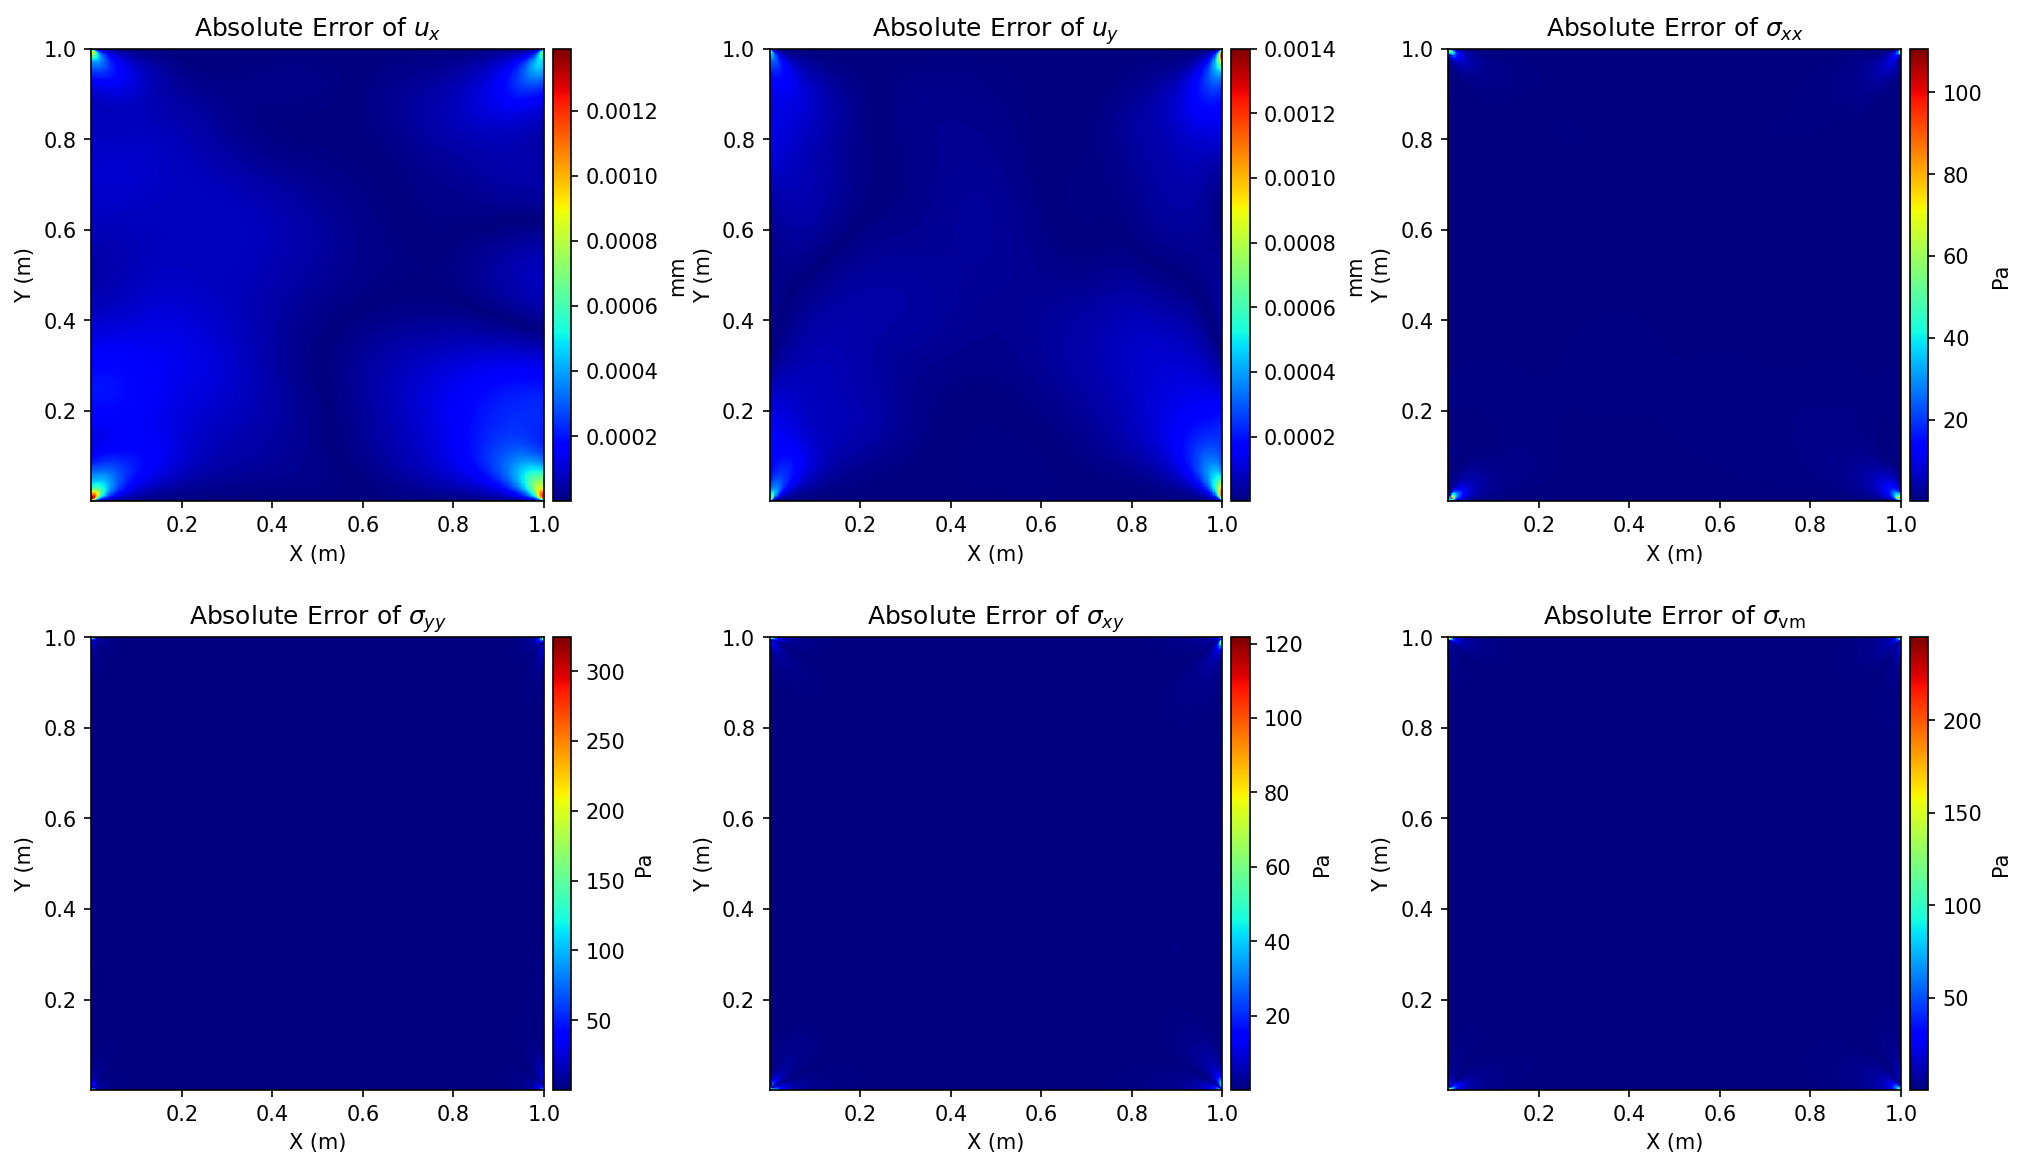

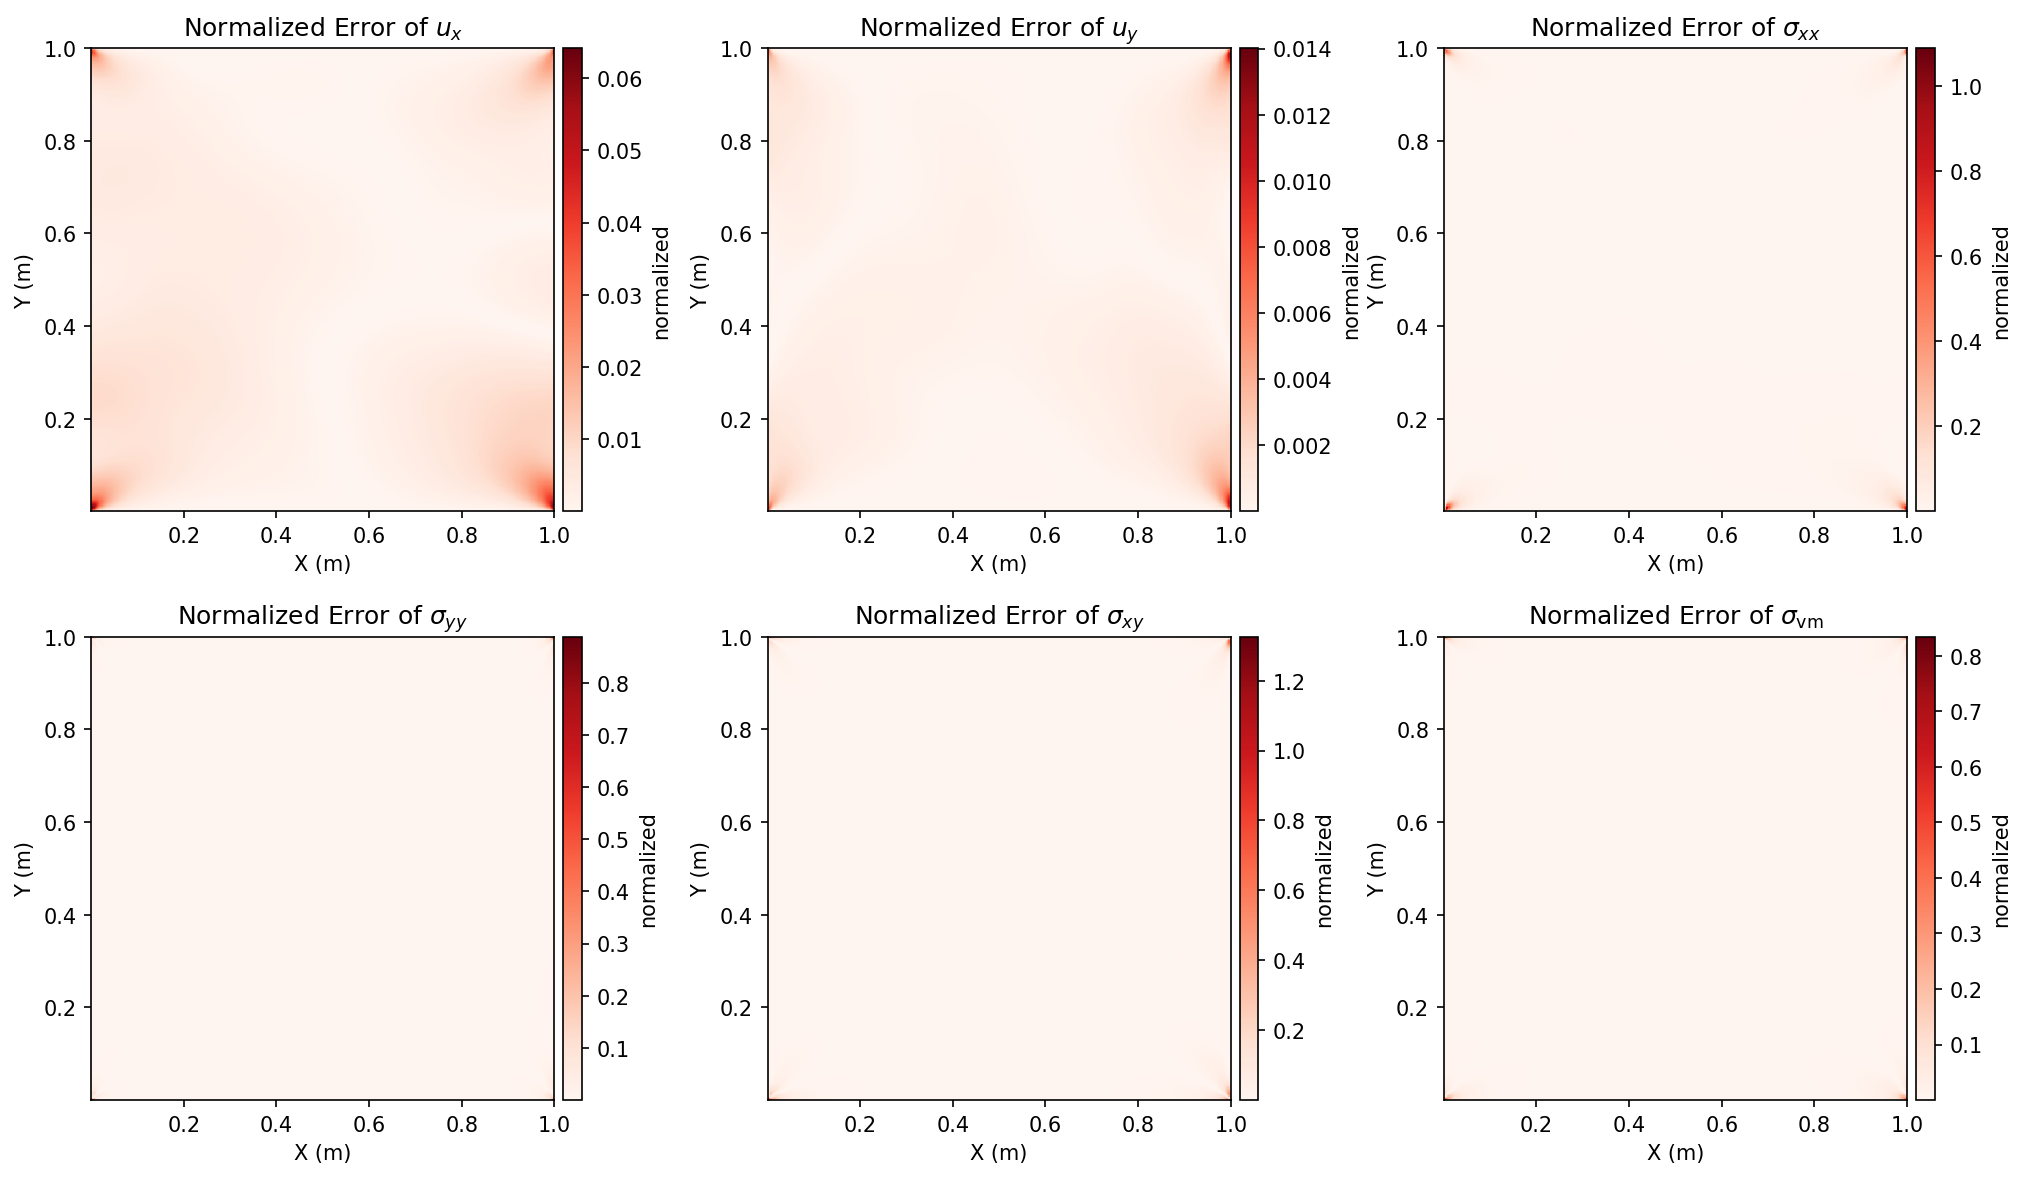

In [3]:
# ==========================================
# 7. D-PINN 相对于 COMSOL 参考解的六物理量误差分析
# ==========================================
print("计算 D-PINN 相对于 COMSOL 参考解的六物理量 L2 误差、绝对误差云图和归一化误差云图...")


from pathlib import Path

COMSOL_REF_PATH = Path(r"C:\Users\magic\Desktop\KM-PIKFNN\方板受压\方板受压comsol.txt")

def load_comsol_reference_table(txt_path=COMSOL_REF_PATH):
    """读取 COMSOL 电子表格 txt：X, Y, u, v, sx, sy, sxy, mises。"""
    txt_path = Path(txt_path)
    if not txt_path.exists():
        raise FileNotFoundError(f"找不到 COMSOL 参考解文件: {txt_path}")

    data = np.loadtxt(txt_path, comments="%")
    if data.ndim != 2 or data.shape[1] < 8:
        raise ValueError(f"COMSOL 文件至少需要 8 列，当前 shape={data.shape}")

    return {
        "points": data[:, 0:2].astype(np.float32),
        "x": data[:, 0],
        "y": data[:, 1],
        "ux": data[:, 2],
        "uy": data[:, 3],
        "sxx": data[:, 4],
        "syy": data[:, 5],
        "sxy": data[:, 6],
        "von_mises": data[:, 7],
        "raw": data,
    }

def regular_grid_from_points(points, values, decimals=12):
    points = np.asarray(points, dtype=float)
    values = np.asarray(values, dtype=float).reshape(-1)
    xr = np.round(points[:, 0], decimals)
    yr = np.round(points[:, 1], decimals)
    xs = np.unique(xr)
    ys = np.unique(yr)

    if xs.size * ys.size != values.size:
        raise ValueError(
            f"COMSOL 点不是规则网格: nx={xs.size}, ny={ys.size}, n={values.size}"
        )

    grid = np.full((ys.size, xs.size), np.nan, dtype=float)
    ix = np.searchsorted(xs, xr)
    iy = np.searchsorted(ys, yr)
    grid[iy, ix] = values
    if np.isnan(grid).any():
        raise ValueError("规则网格存在缺失点，请检查 COMSOL 导出数据。")
    return xs, ys, grid

def _add_equal_height_colorbar(fig, ax, im, label):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.06)
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label(label)
    return cbar

def relative_l2_error(pred, ref):
    pred = np.asarray(pred).reshape(-1)
    ref = np.asarray(ref).reshape(-1)
    return float(np.linalg.norm(pred - ref, 2) / max(np.linalg.norm(ref, 2), 1e-15))

def normalized_abs_error(pred, ref):
    pred = np.asarray(pred).reshape(-1)
    ref = np.asarray(ref).reshape(-1)
    return np.abs(pred - ref) / max(np.max(np.abs(ref)), 1e-15)

FIELD_ORDER = ["ux", "uy", "sxx", "syy", "sxy", "von_mises"]
FIELD_LABELS = {
    "ux": r"$u_x$",
    "uy": r"$u_y$",
    "sxx": r"$\sigma_{xx}$",
    "syy": r"$\sigma_{yy}$",
    "sxy": r"$\sigma_{xy}$",
    "von_mises": r"$\sigma_{\mathrm{vm}}$",
}
ABS_UNITS = {
    "ux": "mm",
    "uy": "mm",
    "sxx": "Pa",
    "syy": "Pa",
    "sxy": "Pa",
    "von_mises": "Pa",
}
ABS_SCALE = {
    "ux": 1e3,
    "uy": 1e3,
    "sxx": 1.0,
    "syy": 1.0,
    "sxy": 1.0,
    "von_mises": 1.0,
}

def build_six_field_error_data(pred, ref):
    metrics = {}
    absolute_errors_for_plot = {}
    normalized_errors = {}

    for key in FIELD_ORDER:
        pred_values = np.asarray(pred[key]).reshape(-1)
        ref_values = np.asarray(ref[key]).reshape(-1)
        abs_err = np.abs(pred_values - ref_values)
        norm_err = normalized_abs_error(pred_values, ref_values)

        metrics[f"L2_{key}"] = relative_l2_error(pred_values, ref_values)
        metrics[f"Max_abs_error_{key}"] = float(np.max(abs_err))
        metrics[f"Max_normalized_error_{key}"] = float(np.max(norm_err))

        absolute_errors_for_plot[key] = abs_err * ABS_SCALE[key]
        normalized_errors[key] = norm_err

    return metrics, absolute_errors_for_plot, normalized_errors

def print_six_field_error_table(method_name, metrics):
    print("-" * 92)
    print(f"{method_name} vs COMSOL six-field errors")
    print("-" * 92)
    print(f"{'Field':>12} {'Relative L2':>16} {'Max abs error':>18} {'Max norm error':>18}")
    print("-" * 92)
    for key in FIELD_ORDER:
        print(
            f"{key:>12} "
            f"{metrics[f'L2_{key}']:16.4e} "
            f"{metrics[f'Max_abs_error_{key}']:18.4e} "
            f"{metrics[f'Max_normalized_error_{key}']:18.4e}"
        )
    print("-" * 92)

    try:
        import pandas as pd
        table = pd.DataFrame([
            {
                "field": key,
                "relative_L2": metrics[f"L2_{key}"],
                "max_abs_error": metrics[f"Max_abs_error_{key}"],
                "max_normalized_error": metrics[f"Max_normalized_error_{key}"],
            }
            for key in FIELD_ORDER
        ])
        display(table)
        return table
    except Exception:
        return None

def plot_six_field_error_clouds(points, error_fields, title_prefix, colorbar_label, cmap, save_path):
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.0), dpi=150)
    for ax, key in zip(axes.ravel(), FIELD_ORDER):
        xs, ys, grid_values = regular_grid_from_points(points, error_fields[key])
        im = ax.pcolormesh(xs, ys, grid_values, shading="auto", cmap=cmap)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"{title_prefix} {FIELD_LABELS[key]}")
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        label = ABS_UNITS[key] if colorbar_label == "absolute" else "normalized"
        _add_equal_height_colorbar(fig, ax, im, label)

    fig.tight_layout()
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"误差云图已保存: {save_path}")
    return fig


def predict_dpinn_fields_on_points(model, pts, batch_size=10000):
    """在 COMSOL 坐标点上预测 D-PINN 的 ux, uy, sigma_xx, sigma_yy, sigma_xy, von Mises。"""
    model.eval()
    pts = np.asarray(pts, dtype=np.float32)
    try:
        model_device = next(model.parameters()).device
    except StopIteration:
        model_device = torch.device("cpu")

    ux_chunks, uy_chunks = [], []
    sxx_chunks, syy_chunks, sxy_chunks = [], [], []
    stress_scale = E_real / scale_u
    # 注意：BEM/COMSOL 参考解单元会覆盖全局 lam 为真实量纲值。
    # D-PINN 模型训练使用的是归一化 E*=1 的 Lamé 常数，误差评估必须固定用局部归一化参数。
    E_star_for_pinn = 1.0
    lam_star = (E_star_for_pinn * nu) / ((1.0 + nu) * (1.0 - 2.0 * nu))
    mu_star = E_star_for_pinn / (2.0 * (1.0 + nu))

    for start in range(0, pts.shape[0], int(batch_size)):
        end = min(start + int(batch_size), pts.shape[0])
        batch = pts[start:end]

        x = torch.tensor(batch[:, 0:1], dtype=torch.float32, device=model_device, requires_grad=True)
        y = torch.tensor(batch[:, 1:2], dtype=torch.float32, device=model_device, requires_grad=True)

        u_pred, v_pred = model(x, y)

        u_x = grad(u_pred, x)
        u_y = grad(u_pred, y)
        v_x = grad(v_pred, x)
        v_y = grad(v_pred, y)

        sig_xx_pred = (lam_star + 2.0 * mu_star) * u_x + lam_star * v_y
        sig_yy_pred = (lam_star + 2.0 * mu_star) * v_y + lam_star * u_x
        sig_xy_pred = mu_star * (u_y + v_x)

        ux_chunks.append(u_pred.detach().cpu().numpy().reshape(-1) / scale_u)
        uy_chunks.append(v_pred.detach().cpu().numpy().reshape(-1) / scale_u)
        sxx_chunks.append(sig_xx_pred.detach().cpu().numpy().reshape(-1) * stress_scale)
        syy_chunks.append(sig_yy_pred.detach().cpu().numpy().reshape(-1) * stress_scale)
        sxy_chunks.append(sig_xy_pred.detach().cpu().numpy().reshape(-1) * stress_scale)

        del x, y, u_pred, v_pred, u_x, u_y, v_x, v_y, sig_xx_pred, sig_yy_pred, sig_xy_pred
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    ux_real = np.concatenate(ux_chunks)
    uy_real = np.concatenate(uy_chunks)
    sxx_real = np.concatenate(sxx_chunks)
    syy_real = np.concatenate(syy_chunks)
    sxy_real = np.concatenate(sxy_chunks)

    # COMSOL 当前为 plane strain。
    szz_real = nu * (sxx_real + syy_real)
    mises_real = np.sqrt(
        0.5 * ((sxx_real - syy_real)**2 +
               (syy_real - szz_real)**2 +
               (szz_real - sxx_real)**2) +
        3.0 * sxy_real**2
    )

    return {
        "ux": ux_real,
        "uy": uy_real,
        "sxx": sxx_real,
        "syy": syy_real,
        "sxy": sxy_real,
        "von_mises": mises_real,
    }

if "model" not in globals():
    raise RuntimeError("请先运行 D-PINN 训练单元，确保变量 model 已经存在。")

dpinn_comsol_ref = load_comsol_reference_table(COMSOL_REF_PATH)
dpinn_comsol_pred = predict_dpinn_fields_on_points(
    model,
    dpinn_comsol_ref["points"],
    batch_size=DPINN_PRED_BATCH_SIZE if "DPINN_PRED_BATCH_SIZE" in globals() else 10000,
)

dpinn_error_metrics, dpinn_abs_errors, dpinn_normalized_errors = build_six_field_error_data(
    dpinn_comsol_pred,
    dpinn_comsol_ref,
)
dpinn_error_table = print_six_field_error_table("D-PINN", dpinn_error_metrics)

# 兼容原来可能手动使用的变量名
u_pred_bem_real = dpinn_comsol_pred["ux"]
v_pred_bem_real = dpinn_comsol_pred["uy"]
u_bem_ref = dpinn_comsol_ref["ux"]
v_bem_ref = dpinn_comsol_ref["uy"]
err_ux_norm = dpinn_normalized_errors["ux"]
err_uy_norm = dpinn_normalized_errors["uy"]
L2_ux = dpinn_error_metrics["L2_ux"]
L2_uy = dpinn_error_metrics["L2_uy"]
L2_sxx = dpinn_error_metrics["L2_sxx"]
L2_syy = dpinn_error_metrics["L2_syy"]
L2_sxy = dpinn_error_metrics["L2_sxy"]
L2_von_mises = dpinn_error_metrics["L2_von_mises"]

DPINN_COMSOL_ERROR_OUT_DIR = Path("dpinn_comsol_error_clouds")
fig_dpinn_abs_error = plot_six_field_error_clouds(
    dpinn_comsol_ref["points"],
    dpinn_abs_errors,
    title_prefix="Absolute Error of",
    colorbar_label="absolute",
    cmap="jet",
    save_path=DPINN_COMSOL_ERROR_OUT_DIR / "dpinn_comsol_absolute_error_6_fields.png",
)
fig_dpinn_norm_error = plot_six_field_error_clouds(
    dpinn_comsol_ref["points"],
    dpinn_normalized_errors,
    title_prefix="Normalized Error of",
    colorbar_label="normalized",
    cmap="Reds",
    save_path=DPINN_COMSOL_ERROR_OUT_DIR / "dpinn_comsol_normalized_error_6_fields.png",
)

plt.show()
